
## Script for Exercise 4 ("Battery energy storage system in the grid vs. grid investments") 

Intro script for Exercise 4 in specialization course module 
"Flexibility in power grid operation and planning" at NTNU (TET4565/TET4575) 

In [1]:
# Dependencies

import pandas as pd
import os
import load_profiles as lp
import pandapower_read_csv as ppcsv

In [2]:
# Define input data

# Location of (processed) data set for CINELDI MV reference system
# (to be replaced by your own local data folder)
path_data_set         = 'C:/Users/Eier/OneDrive - NTNU/9. Semester/Fordypningsemne, Kraftmarkeder/Module 1, Flexibility/7703070'

filename_load_data_fullpath = os.path.join(path_data_set,'load_data_CINELDI_MV_reference_system.csv')
filename_load_mapping_fullpath = os.path.join(path_data_set,'mapping_loads_to_CINELDI_MV_reference_grid.csv')
filename_standard_overhead_lines = os.path.join(path_data_set,'standard_overhead_line_types.csv')
filename_reldata = os.path.join(path_data_set,'reldata_for_component_types.csv')
filename_load_point = os.path.join(path_data_set,'CINELDI_MV_reference_system_load_point.csv')

# Subset of load buses to consider in the grid area, considering the area at the end of the main radial in the grid
bus_i_subset = [90, 91, 92, 96]

# Assumed power flow limit in MW that limit the load demand in the grid area (through line 85-86)
P_lim = 4

# Factor to scale the loads for this exercise compared with the base version of the CINELDI reference system data set
scaling_factor = 10

# Read standard data for overhead lines
data_standard_overhead_lines = pd.read_csv(filename_standard_overhead_lines, delimiter=';')
data_standard_overhead_lines.set_index(keys = 'type', drop = True, inplace = True)

# Read standard component reliability data
data_comp_rel = pd.read_csv(filename_reldata, delimiter=';')
data_comp_rel.set_index(keys = 'main_type', drop = True, inplace = True)

# Read load point data (incl. specific rates of costs of energy not supplied) for data
data_load_point = pd.read_csv(filename_load_point, delimiter=';')
data_load_point.set_index(keys = 'bus_i', drop = True, inplace = True)

In [3]:
# Read pandapower network

net = ppcsv.read_net_from_csv(path_data_set, baseMVA=10)

c:\Users\Eier\OneDrive - NTNU\9. Semester\Fordypningsemne, Kraftmarkeder\Module 1, Flexibility\CINELDI_MV_reference_system-flexibility_course_NTNU_public\pandapower_read_csv.py:123: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_bus = pd.concat([res_bus, res_row])


In [4]:

load_profiles = lp.load_profiles(filename_load_data_fullpath)

# Consider only the day with the peak load in the area (28 February)
repr_days = [31+28]

# Get relative load profiles for representative days mapped to buses of the CINELDI test network;
# the column index is the bus number (1-indexed) and the row index is the hour of the year (0-indexed)
profiles_mapped = load_profiles.map_rel_load_profiles(filename_load_mapping_fullpath,repr_days)

# Calculate load time series in units MW (or, equivalently, MWh/h) by scaling the normalized load time series by the
# maximum load value for each of the load points in the grid data set (in units MW); the column index is the bus number
# (1-indexed) and the row index is the hour of the year (0-indexed)
load_time_series_mapped = profiles_mapped.mul(net.load['p_mw'])

c:\Users\Eier\OneDrive - NTNU\9. Semester\Fordypningsemne, Kraftmarkeder\Module 1, Flexibility\CINELDI_MV_reference_system-flexibility_course_NTNU_public\load_profiles.py:46: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  loaddata.index = pd.to_datetime([d + " " + "%.2d" % (int(t) - 1) for d, t in timestamp_list], dayfirst=True)
c:\Users\Eier\OneDrive - NTNU\9. Semester\Fordypningsemne, Kraftmarkeder\Module 1, Flexibility\CINELDI_MV_reference_system-flexibility_course_NTNU_public\load_profiles.py:87: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  profile_days = pd.concat([profile_days, profile_day])
c:\Users\Eier\OneDrive - NTNU\9. Se

In [5]:
# Aggregate the load demand in the area

# Aggregated load time series for the subset of load buses
load_time_series_subset = load_time_series_mapped[bus_i_subset] * scaling_factor
load_time_series_subset_aggr = load_time_series_subset.sum(axis=1)

P_max = load_time_series_subset_aggr.max()

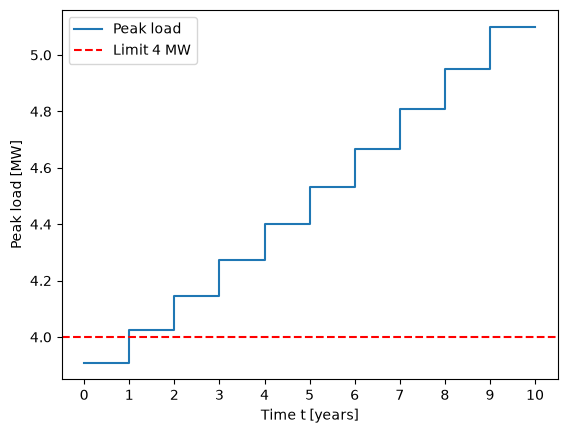

Peak load in start of year 1: 3.9088690601282443
Peak load in start of year 2: 4.026135131932092


In [6]:
#Task 2: Show that some grid planning measure is needed at the beginning of year 2

import matplotlib.pyplot as plt

P_peak = []# peak load for each year [MW]
g=0.03 # peak load grows 3 % per year

for y in range(10):# y = 0, 1,.., 9
    P_peak.append(P_max * (1 + g)**y)

t = list(range(11))# t = 0, 1,.., 10 [years]
P_plot = P_peak + [P_peak[-1]]# repeat last value so year 10 is shown

plt.step(t, P_plot, where='post', label='Peak load')
plt.axhline(P_lim, color='r', linestyle='--', label='Limit 4 MW')
plt.xlabel('Time t [years]')
plt.ylabel('Peak load [MW]')
plt.xticks(t)
plt.legend()
plt.show()

print('Peak load in start of year 1:', P_peak[0])
print('Peak load in start of year 2:', P_peak[1])

In [7]:
print(data_standard_overhead_lines)

                                    R_ohm_per_km  X_ohm_per_km  Cd_nF_per_km  \
type                                                                           
40-AL1/7-ST1A (FeAl nr. 25 6/1)            0.723         0.394         9.226   
80-AL1/13-ST1A (FeAl nr. 50 6/1)           0.360         0.373         9.793   
111-AL1/19-ST1A (FeAl nr. 70 6/1)          0.258         0.362        10.100   

                                    Imax_A  cost_NOK_per_km  
type                                                         
40-AL1/7-ST1A (FeAl nr. 25 6/1)        266           605173  
80-AL1/13-ST1A (FeAl nr. 50 6/1)       416           697375  
111-AL1/19-ST1A (FeAl nr. 70 6/1)      517           759408  


In [8]:
#Task 3: Estimate the grid investment costs for grid planning alternative A

length_MF = 20# length of main feeder [km]

cost_per_km = data_standard_overhead_lines['cost_NOK_per_km'].iloc[2]# FeAl 70 is row 2 (third row) [NOK/km]
C_inv = cost_per_km * length_MF# investment cost [NOK]

print('Investment cost =', C_inv, 'NOK')

Investment cost = 15188160 NOK


In [9]:
#Task 4: Calculate the present value of the investment costs assuming a discount rate of 4%

r = 0.04# discount rate [-]
t_inv_A = 1# investment at the beginning of year 2 [years]

PV_inv = C_inv / (1 + r)**t_inv_A# present value of investment [NOK]

print('Present value of investment =', PV_inv, 'NOK')

Present value of investment = 14604000.0 NOK


In [10]:
#Task 5:  Calculate the residual value and the corrected present value of the grid investment cost

y_end = 20# analysis horizon [years]
T_life = 40# economic lifetime of the new line [years]

C_inv_res = C_inv * (1 - (y_end - t_inv_A) / T_life)# residual value at y_end [NOK]
PV_res = C_inv_res / (1 + r)**y_end# present value of residual value [NOK]
PV_inv_corr = PV_inv - PV_res# corrected present value [NOK]

print('Residual value =', C_inv_res, 'NOK')
print('PV of residual value =', PV_res, 'NOK')
print('Corrected PV of investment =', PV_inv_corr, 'NOK')

Residual value = 7973784.0 NOK
PV of residual value = 3639130.929428724 NOK
Corrected PV of investment = 10964869.070571275 NOK


Grid investment needed at t = 9
Peak load at t = 5.100187528755157 MW


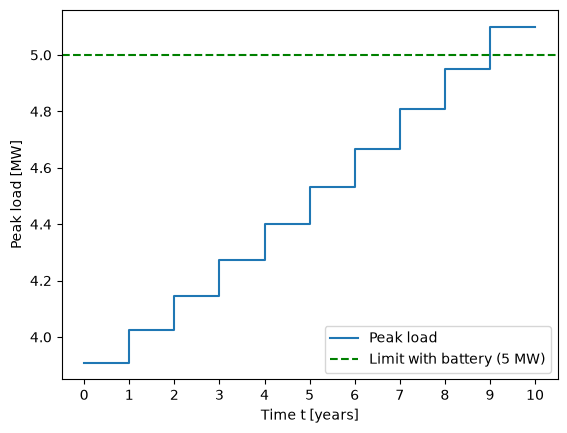

Residual value = 11011416.0 NOK
Corrected PV (B) = 5645533.232256924 NOK
Reduction compared with A = 5319335.838314352 NOK


In [11]:
#Task 6: Find how a battery in the grid can postpone grid investments and reduce its present value
P_bat = 1 # battery power capacity [MW]
P_lim_bat = P_lim + P_bat # limit with battery [MW]

# Find the first year where the peak load exceeds the limit with battery
for t in range(20):
    if P_peak[t] > P_lim_bat:
        t_inv_B = t # time of grid investment [years]
        break

print('Grid investment needed at t =', t_inv_B)
print('Peak load at t =', P_peak[t_inv_B], 'MW')

#Plotting to show where the need for grid reinforcement is 
t = list(range(11)) #10 years
P_plot = P_peak + [P_peak[-1]] 

plt.step(t, P_plot, where='post', label='Peak load')
plt.axhline(P_lim + P_bat, color='g', linestyle='--', label='Limit with battery (5 MW)')
plt.xlabel('Time t [years]')
plt.ylabel('Peak load [MW]')
plt.xticks(t)
plt.legend()
plt.show()


# Corrected present value (same as task 5, but with t_inv_B)
C_inv_res_B = C_inv * (1 - (y_end - t_inv_B) / T_life)# residual value [NOK]
PV_inv_B = C_inv / (1 + r)**t_inv_B# PV of investment [NOK]
PV_res_B = C_inv_res_B / (1 + r)**y_end # PV of residual value [NOK]
PV_inv_corr_B = PV_inv_B - PV_res_B# corrected PV [NOK]

print('Residual value =', C_inv_res_B, 'NOK')
print('Corrected PV (B) =', PV_inv_corr_B, 'NOK')
print('Reduction compared with A =', PV_inv_corr - PV_inv_corr_B, 'NOK')

In [12]:
#Task 7: Estimate the annual operational costs of using battery for congestion management

import numpy as np

P_h = load_time_series_subset_aggr.values #load each hour on 28 February [MW]
C_op_B = [] #annual cost for each year [NOK]

for t in range(10):
    P_over = np.maximum(0, P_h * 1.03**t - P_lim) #load above 4 MW each hour [MW]
    E_shift = P_over.sum() #energy shifted per day [MWh]

    if t >= t_inv_B:# grid reinforced, battery not used
        E_shift = 0

    C_op_B.append(2000 * E_shift * 20) # 2000 NOK/MWh, 20 days per year
    print('t =', t, '| E_shift =', round(E_shift, 2), 'MWh/day | cost =', round(2000 * E_shift * 20), 'NOK/year')

t = 0 | E_shift = 0.0 MWh/day | cost = 0 NOK/year
t = 1 | E_shift = 0.03 MWh/day | cost = 1045 NOK/year
t = 2 | E_shift = 0.18 MWh/day | cost = 7396 NOK/year
t = 3 | E_shift = 0.54 MWh/day | cost = 21594 NOK/year
t = 4 | E_shift = 1.18 MWh/day | cost = 47181 NOK/year
t = 5 | E_shift = 2.23 MWh/day | cost = 89222 NOK/year
t = 6 | E_shift = 3.63 MWh/day | cost = 145182 NOK/year
t = 7 | E_shift = 5.43 MWh/day | cost = 217099 NOK/year
t = 8 | E_shift = 7.54 MWh/day | cost = 301750 NOK/year
t = 9 | E_shift = 0 MWh/day | cost = 0 NOK/year


In [13]:
#Task 8: Estimate the annual costs of energy not supplied for grid planning alternative A

#Implemented code from Exercise 3, Task 1. 
length_MF = 20 #length of main feeder [km]

lambda_perm = data_comp_rel['lambda_perm'].iloc[0] # failure rate, overhead line [failures per 100 km per year]
r_perm = data_comp_rel['r_perm'].iloc[0]# outage time per failure [h per failure]

lambda_MF = lambda_perm * length_MF / 100# failure rate of main feeder.

# Same as Exercise 3, Task 2 
P_i_max = net.load.loc[bus_i_subset, 'p_mw'] # peak load per bus (from the data set)   # CHANGED: P_max -> P_i_max, since P_max is already used in Exercise 4
weight= P_i_max / P_i_max.sum()                                                         

# c_i: Average specific interruption cost per bus [NOK/kWh], r = 3 h closest to 4 h, so using the 4h column
c_i = data_load_point.loc[bus_i_subset, 'c_NOK_per_kWh_4h']

CENS_A = [] # CHANGED: list to store CENS for each year [NOK/year]

for t in range(10): # CHANGED: repeat for each year in the planning horizon, year 10-20 not included since line is reinforced. 
    P_avg = 1.841 * 1.03**t # CHANGED: average load grows 3 % per year (was P_avg = 1.841)
    P_i = P_avg * weight

    EENS_i = lambda_MF * r_perm * P_i #[MWh/year]

    # CENS = sum_i c_i * EENS_i [NOK/year]
    # Multiply by 1000 to convert EENS from MWh to kWh, since c_i is given in NOK/kWh
    CENS = (c_i * EENS_i * 1000).sum()

    CENS_A.append(CENS) # save CENS for this year
    print('t =', t, 'CENS =', round(CENS), 'NOK/year') 

t = 0 CENS = 237221 NOK/year
t = 1 CENS = 244338 NOK/year
t = 2 CENS = 251668 NOK/year
t = 3 CENS = 259218 NOK/year
t = 4 CENS = 266995 NOK/year
t = 5 CENS = 275004 NOK/year
t = 6 CENS = 283255 NOK/year
t = 7 CENS = 291752 NOK/year
t = 8 CENS = 300505 NOK/year
t = 9 CENS = 309520 NOK/year


In [14]:
#Task 9: Estimate the annual costs of energy not supplied for grid planning alternative B

#Same as Exercise 3, Task 3 
E_cap_bat = 2 # battery energy capacity [MWh]. During a 3 h outage the battery could give 1 MW * 3 h = 3 MWh, but it only stores 2 MWh.

CENS_B = [] # CHANGED: list to store CENS for each year [NOK/year]

for t in range(10): # CHANGED: repeat for each year in the planning horizon
    P_avg = 1.841 * 1.03**t # CHANGED: average load grows 3 % per year
    P_i = P_avg * weight

    if 1 <= t < t_inv_B: # CHANGED: battery only available from t = 1 until the line is reinforced (t = 9)
        EENS_i_bat = lambda_MF * (r_perm * P_i - E_cap_bat * weight) # same as Exercise 3, Task 3
    else:
        EENS_i_bat = lambda_MF * r_perm * P_i # CHANGED: no battery, same as task 8

    CENS_bat = (c_i * EENS_i_bat * 1000).sum()

    CENS_B.append(CENS_bat) # CHANGED: save CENS for this year
    print('t =', t, 'CENS =', round(CENS_bat), 'NOK/year')

t = 0 CENS = 237221 NOK/year
t = 1 CENS = 158435 NOK/year
t = 2 CENS = 165765 NOK/year
t = 3 CENS = 173315 NOK/year
t = 4 CENS = 181092 NOK/year
t = 5 CENS = 189101 NOK/year
t = 6 CENS = 197352 NOK/year
t = 7 CENS = 205849 NOK/year
t = 8 CENS = 214602 NOK/year
t = 9 CENS = 309520 NOK/year


In [15]:
#Task 10: 

# Table with cost elements for each year
table_A = pd.DataFrame({
    'Year': range(1, 11),
    'Investment [NOK]': [0, C_inv, 0, 0, 0, 0, 0, 0, 0, 0], # investment at the beginning of year 2
    'Flexibility [NOK]': [0] * 10, # no battery in alternative A
    'CENS [NOK]': CENS_A}) # from task 8
print(table_A)

# Present value of CENS (operational costs are discounted from the end of each year-->(t+1))
PV_CENS_A = 0
for t in range(10):
    PV_CENS_A += CENS_A[t] / (1 + r)**(t + 1) # year t+1 is discounted with (1 + r)^(t+1)

PV_tot_A = PV_inv_corr + PV_CENS_A # total present value [NOK]

print('PV of CENS =', PV_CENS_A, 'NOK')
print('Total PV (A) =', PV_tot_A, 'NOK')

   Year  Investment [NOK]  Flexibility [NOK]     CENS [NOK]
0     1                 0                  0  237221.215631
1     2          15188160                  0  244337.852100
2     3                 0                  0  251667.987663
3     4                 0                  0  259218.027293
4     5                 0                  0  266994.568112
5     6                 0                  0  275004.405155
6     7                 0                  0  283254.537310
7     8                 0                  0  291752.173429
8     9                 0                  0  300504.738632
9    10                 0                  0  309519.880791
PV of CENS = 2184765.8399567953 NOK
Total PV (A) = 13149634.910528071 NOK


In [16]:
#Task 11: Calculate total present value of the socio-economic costs of grid planning alternative B

# Table with cost elements for each year 
table_B = pd.DataFrame({
    'Year': range(1, 11),
    'Investment [NOK]': [0, 0, 0, 0, 0, 0, 0, 0, 0, C_inv],# investment at the beginning of year 10
    'Flexibility [NOK]': C_op_B, # from task 7
    'CENS [NOK]': CENS_B}) # from task 9
print(table_B)

# Present value of flexibility costs and CENS (discounted from the end of each year)
PV_flex_B = 0
PV_CENS_B = 0
for t in range(10):
    PV_flex_B += C_op_B[t] / (1 + r)**(t + 1)
    PV_CENS_B += CENS_B[t] / (1 + r)**(t + 1)

PV_tot_B = PV_inv_corr_B + PV_flex_B + PV_CENS_B   # total present value [NOK]

print('PV of investment (corrected) =', PV_inv_corr_B, 'NOK')
print('PV of flexibility =', PV_flex_B, 'NOK')
print('PV of CENS =', PV_CENS_B, 'NOK')
print('Total PV (B) =', PV_tot_B, 'NOK')
print('Difference A - B =', PV_tot_A - PV_tot_B, 'NOK')

   Year  Investment [NOK]  Flexibility [NOK]     CENS [NOK]
0     1                 0           0.000000  237221.215631
1     2                 0        1045.405277  158434.822721
2     3                 0        7395.748563  165764.958284
3     4                 0       21593.522559  173314.997914
4     5                 0       47181.390582  181091.538733
5     6                 0       89221.718741  189101.375776
6     7                 0      145181.768271  197351.507931
7     8                 0      217099.298194  205849.144050
8     9                 0      301749.727312  214601.709253
9    10          15188160           0.000000  309519.880791
PV of investment (corrected) = 5645533.232256924 NOK
PV of flexibility = 616256.3456931675 NOK
PV of CENS = 1628647.3968822889 NOK
Total PV (B) = 7890436.97483238 NOK
Difference A - B = 5259197.935695691 NOK
